# Colab 01: Data and Metrics

**Purpose:** understand the dataset that every other notebook uses.
1. Load the data.
2. Show how the benefit model turns a learner profile into numbers.
3. Look at the prerequisite graphs.
4. Summarise the dataset (sizes, qubits, time budgets).
5. Show the case study.
6. Demonstrate the metrics we use in the paper.

**Paper sections fed by this notebook:** Experimental Setup (instance generation, profiles, metrics).

## 0. Setup

In [7]:
import os, sys, subprocess

REPO_URL  = "https://github.com/<your-username>/qaoa-learning-path-optimization.git"  # <-- change this
REPO_NAME = "qaoa-learning-path-optimization"

# Make sure we are in the repo root (works in Colab and on your own computer)
if not os.path.exists("src"):
    if os.path.exists("../src"):
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_NAME)
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from src.instances import load_instances, benefit
from src.metrics import (total_benefit, time_used, utilization,
                         prereq_fraction, is_feasible, optimality_gap)
from src.solvers import exact_solver, greedy_basic, fixed_curriculum

os.makedirs("results", exist_ok=True)
SEED = 42
np.random.seed(SEED)
print("Working folder:", os.getcwd())

Working folder: /Users/aniketpathak/Desktop/QAOA-learning-path-optimization


## 1. Load the data
Three files: the **main** set (n = 8, for RQ1 and RQ2), the **scaling** set (n = 6 to 12, for RQ3), and the **case study** (a realistic 10-module path).

In [8]:
main  = load_instances("data/instances_main.json")
scal  = load_instances("data/instances_scaling.json")
case  = load_instances("data/case_study.json")
print("main instances   :", len(main))
print("scaling instances:", len(scal))
print("case-study learners:", len(case))

main instances   : 541
scaling instances: 240
case-study learners: 3


## 2. One instance, up close
An instance is just a few lists: `t` (study time per module), `b` (benefit), `E` (prerequisite pairs) and the budget `T`.
An edge `(i, j)` means *module i must be studied before module j*.

In [9]:
inst = main[0]
print("profile:", inst["profile"], "| modules:", inst["n"], "| time budget T:", inst["T"],
      "| total time of all modules:", sum(inst["t"]))
print("prerequisite edges (i -> j):", inst["E"])

pd.DataFrame({"time t": inst["t"], "benefit b": inst["b"]}).rename_axis("module")

profile: beginner | modules: 8 | time budget T: 5 | total time of all modules: 18
prerequisite edges (i -> j): [(0, 5), (1, 2), (3, 5), (3, 7)]


,time t,benefit b
module,,
0,1,2.8357
1,3,1.1556
2,2,6.1391
3,2,3.6695
4,3,0.5138
5,3,4.7578
6,3,6.0750
7,1,2.2891


## 3. The benefit model
Each module's benefit is **b = w × (1 − m) × r**
- `w` importance of the module,
- `m` how much the learner already knows (mastery, 0 to 1),
- `r` how relevant it is to the learner's goal (0 to 1).

Worked example for one module with importance 8:

In [10]:
w = 8
for name, m, r in [("knows nothing, very relevant", 0.0, 1.0),
                   ("half known, very relevant",    0.5, 1.0),
                   ("fully known",                  1.0, 1.0),
                   ("knows nothing, barely relevant", 0.0, 0.2)]:
    print(f"{name:32s} -> benefit = {float(benefit(w, m, r)):.2f}")

knows nothing, very relevant     -> benefit = 8.00
half known, very relevant        -> benefit = 4.00
fully known                      -> benefit = 0.00
knows nothing, barely relevant   -> benefit = 1.60


### How the three learner profiles differ
Same generator, different mastery/relevance patterns. Boxplot of module benefits for each profile (main set):

               count  mean   std   min   25%   50%   75%   max
profile                                                       
beginner      1440.0  3.70  2.09  0.42  1.90  3.56  5.22  9.80
goal_focused  1440.0  1.95  2.02  0.06  0.56  1.09  2.69  9.69
partial       1440.0  2.06  1.85  0.00  0.55  1.53  2.98  8.76


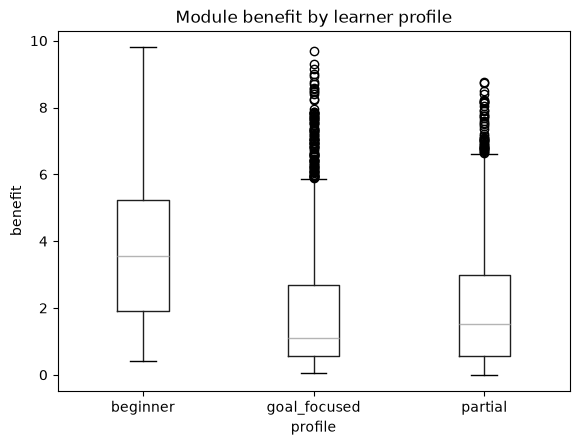

In [11]:
rows = [dict(profile=i["profile"], benefit=v) for i in main if i["profile"] != "trap" for v in i["b"]]
df_b = pd.DataFrame(rows)
print(df_b.groupby("profile").benefit.describe().round(2))

df_b.boxplot(column="benefit", by="profile", grid=False)
plt.suptitle(""); plt.title("Module benefit by learner profile"); plt.ylabel("benefit")
plt.show()

## 4. Prerequisite graphs
Arrows point from a prerequisite to the module that needs it. Left to right = study order.

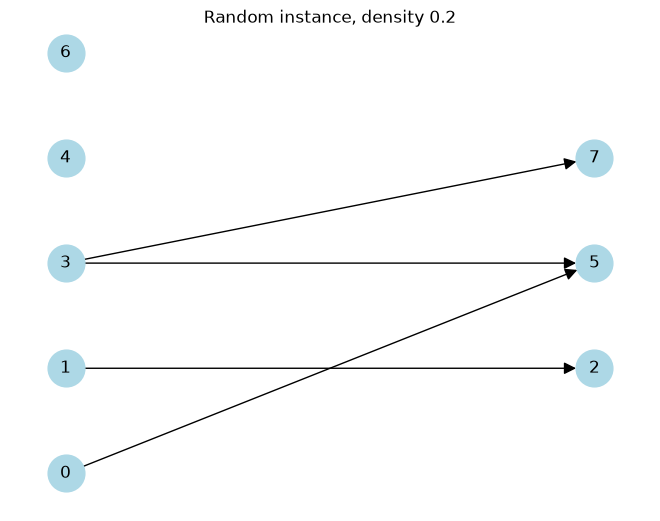

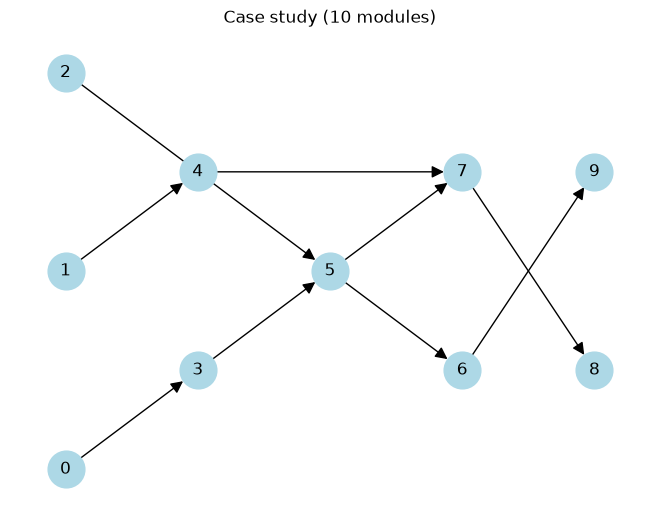

In [12]:
def draw_dag(inst, title):
    G = nx.DiGraph()
    G.add_nodes_from(range(inst["n"]))
    G.add_edges_from(inst["E"])
    for layer, nodes in enumerate(nx.topological_generations(G)):
        for v in nodes:
            G.nodes[v]["layer"] = layer
    pos = nx.multipartite_layout(G, subset_key="layer")
    nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=700, arrowsize=18)
    plt.title(title); plt.show()

draw_dag(main[0], f"Random instance, density {main[0]['density']}")
draw_dag(case[0], "Case study (10 modules)")

## 5. Dataset summary
How many instances, how dense the prerequisites are, and how many qubits QAOA will need.
**Qubits = n + number of slack bits**, where slack bits = ceil(log2(T + 1)).

In [13]:
def qubits(inst):
    return inst["n"] + int(np.ceil(np.log2(inst["T"] + 1)))

def summary(instances):
    return pd.DataFrame([dict(id=i["id"], n=i["n"], profile=i["profile"], rho=i["rho"],
                              density=i["density"], T=i["T"], total_time=sum(i["t"]),
                              edges=len(i["E"]), qubits=qubits(i)) for i in instances])

s_main, s_scal = summary(main), summary(scal)

print("MAIN set: number of instances per profile and rho")
print(s_main[s_main.profile != "trap"].groupby(["profile", "rho"]).size().unstack())
print()
print("MAIN set: average number of prerequisite edges by density setting")
print(s_main[s_main.profile != "trap"].groupby("density").edges.mean().round(1))
print()
print("SCALING set: qubits by number of modules")
print(s_scal.groupby("n").qubits.agg(["min", "max"]))

MAIN set: number of instances per profile and rho
rho           0.3  0.5  0.7
profile                    
beginner       60   60   60
goal_focused   60   60   60
partial        60   60   60

MAIN set: average number of prerequisite edges by density setting
density
0.2     5.6
0.4    11.3
Name: edges, dtype: float64

SCALING set: qubits by number of modules
    min  max
n           
6     9   10
8    11   12
10   14   15
12   16   17


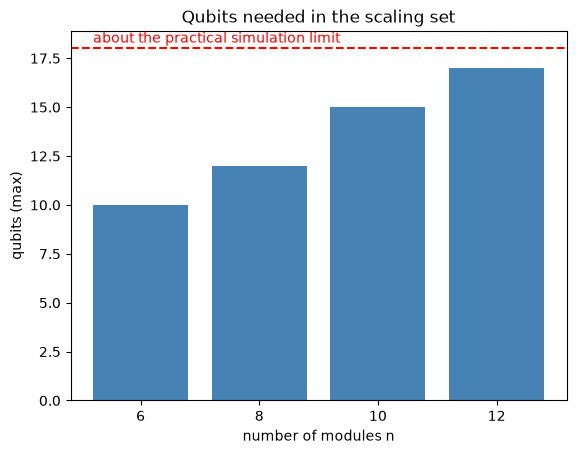

In [14]:
g = s_scal.groupby("n").qubits.max()
plt.bar(g.index.astype(str), g.values, color="steelblue")
plt.axhline(18, ls="--", c="red"); plt.text(-0.4, 18.3, "about the practical simulation limit", color="red")
plt.xlabel("number of modules n"); plt.ylabel("qubits (max)"); plt.title("Qubits needed in the scaling set")
plt.show()

### Time tightness
`rho = T / total time of all modules`. Small rho means the learner can only study a small part of the material.

In [15]:
sub = s_main[s_main.profile != "trap"]
print(sub.groupby("rho").apply(lambda d: (d["T"] / d["total_time"]).mean()).round(2).rename("mean T / total time"))

rho
0.3    0.3
0.5    0.5
0.7    0.7
Name: mean T / total time, dtype: float64


## 6. The case study
A realistic 10-module data-science path. **The values are illustrative assumptions, not real data.**

In [16]:
from src.make_dataset import MODULES, W_MOD
pd.DataFrame({"module": MODULES, "time t": case[0]["t"], "importance w": W_MOD}).rename_axis("index")

,module,time t,importance w
index,,,
0,Python basics,2,6
1,Linear algebra,3,7
2,Probability & statistics,3,8
3,Data handling (pandas),2,6
4,Calculus & optimization,3,6
5,Supervised learning,4,9
6,Model evaluation,2,7
7,Neural networks,4,9
8,Deep learning for vision,3,6


In [17]:
print("Prerequisites:", [(MODULES[i], "->", MODULES[j]) for i, j in case[0]["E"]])
print("Time budget T =", case[0]["T"], "out of", sum(case[0]["t"]))
print()
tab = pd.DataFrame({"module": MODULES})
for c in case:
    tab[c["profile"] + " benefit"] = c["b"]
tab.rename_axis("index").round(2)

Prerequisites: [('Python basics', '->', 'Data handling (pandas)'), ('Linear algebra', '->', 'Calculus & optimization'), ('Probability & statistics', '->', 'Supervised learning'), ('Data handling (pandas)', '->', 'Supervised learning'), ('Supervised learning', '->', 'Model evaluation'), ('Calculus & optimization', '->', 'Neural networks'), ('Supervised learning', '->', 'Neural networks'), ('Neural networks', '->', 'Deep learning for vision'), ('Model evaluation', '->', 'ML deployment')]
Time budget T = 14 out of 28



,module,beginner benefit,partial benefit,goal_vision benefit
index,,,,
0,Python basics,3.36,0.42,0.60
1,Linear algebra,5.60,2.94,4.20
2,Probability & statistics,6.40,1.68,0.96
3,Data handling (pandas),4.80,1.68,1.20
4,Calculus & optimization,4.80,2.94,4.20
5,Supervised learning,7.20,5.67,8.10
6,Model evaluation,5.60,4.90,2.10
7,Neural networks,7.20,6.30,9.00
8,Deep learning for vision,4.80,4.20,6.00


Notice how the same module has very different benefit for different learners. That is the *personalization* in our model.

## 7. The metrics (used in every other notebook)
We take one plan for the hand-made *trap* instance and compute every metric from the paper.

In [18]:
trap = main[-1]                       # the hand-made trap instance is the last one
opt  = exact_solver(trap)
plan = greedy_basic(trap)

for name, r in [("exact (optimal)", opt), ("greedy (basic)", plan), ("fixed curriculum", fixed_curriculum(trap))]:
    x = r["x"]
    print(f"{name:18s} plan={x}  benefit={total_benefit(trap, x):5.1f}  time={time_used(trap, x)}/{trap['T']}"
          f"  utilization={utilization(trap, x):.2f}  prereq satisfied={prereq_fraction(trap, x):.2f}"
          f"  feasible={is_feasible(trap, x)}  gap={optimality_gap(opt['benefit'], r['benefit']):.3f}")

exact (optimal)    plan=[1, 0, 0, 0, 1, 1]  benefit= 16.0  time=8/8  utilization=1.00  prereq satisfied=1.00  feasible=True  gap=0.000
greedy (basic)     plan=[1, 1, 1, 1, 0, 0]  benefit= 11.0  time=7/8  utilization=0.88  prereq satisfied=1.00  feasible=True  gap=0.312
fixed curriculum   plan=[1, 1, 1, 1, 0, 0]  benefit= 11.0  time=7/8  utilization=0.88  prereq satisfied=1.00  feasible=True  gap=0.312


A plan that **breaks** a prerequisite (module 5 chosen without its prerequisite 4) is caught by the metrics:

In [19]:
bad = [0, 0, 0, 0, 0, 1]
print("benefit:", total_benefit(trap, bad), "| prereq satisfied:", prereq_fraction(trap, bad),
      "| feasible:", is_feasible(trap, bad))

benefit: 12.0 | prereq satisfied: 0.0 | feasible: False


## 8. Save a summary table for the paper

In [20]:
out = pd.concat([s_main.assign(set="main"), s_scal.assign(set="scaling")])
out.to_csv("results/dataset_summary.csv", index=False)
print("saved results/dataset_summary.csv with", len(out), "rows")

saved results/dataset_summary.csv with 781 rows


## 9. Still to do in this notebook (later, once Colab 02 and 03 have produced results)
**RQ3 summary:** read `results/exact.csv`, `greedy.csv` and `qaoa.csv`, and show how performance changes with n, prerequisite density and rho.

## What to put in the paper (Experimental Setup)
- Instance generation: times 1 to 4, importance 1 to 10, mastery/relevance per profile, random DAG with density 0.2 or 0.4.
- Dataset sizes: 541 main instances, 240 scaling instances, 1 case study with 3 learners.
- Time budgets: rho = 0.3, 0.5, 0.7. Qubits: 10 to 17.
- All data is synthetic; the case study is illustrative.